In [1]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping


2026-04-26 13:10:36.558191: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777209037.001438      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777209037.117564      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777209038.193603      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777209038.193646      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777209038.193649      55 computation_placer.cc:177] computation placer alr

In [2]:
sdir = '/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images'
filepaths=[]
labels=[]
for folder in os.listdir(sdir):
    for file in os.listdir(os.path.join(sdir, folder)):
        filepaths.append(os.path.join(sdir, folder, file))
        labels.append(folder)
df=pd.DataFrame({'filepaths':filepaths,'labels':labels}).sample(frac=1).reset_index(drop=True)
train_df=df.sample(frac=0.8)
temp_df=df.drop(train_df.index)
valid_df=temp_df.sample(frac=0.5)
test_df=temp_df.drop(valid_df.index)


In [3]:
img_size=(300, 300) 
batch_size=16 

# 1. Get the exact list of all 80 classes from the master dataframe
all_classes = sorted(list(df['labels'].unique()))

# 2. Advanced Data Augmentation
train_datagen=ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.3,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2] # Protects against bad lighting
)
valid_datagen=ImageDataGenerator() 

# 3. Create Generators
train_gen=train_datagen.flow_from_dataframe(train_df,x_col='filepaths',y_col='labels',target_size=img_size,class_mode='categorical',batch_size=batch_size, classes=all_classes)
valid_gen=valid_datagen.flow_from_dataframe(valid_df,x_col='filepaths',y_col='labels',target_size=img_size,class_mode='categorical',batch_size=batch_size, classes=all_classes)


Found 3200 validated image filenames belonging to 80 classes.
Found 400 validated image filenames belonging to 80 classes.


In [4]:
x,y=next(train_gen)
print(x.shape,y.shape)
print(len(train_gen.class_indices))


(16, 300, 300, 3) (16, 80)
80


In [5]:
def make_model(img_size,lr,class_count):
    base_model=EfficientNetB3(include_top=False,weights='imagenet',input_shape=(img_size[0],img_size[1],3),pooling='avg')
    base_model.trainable=False
    x=base_model.output
    x=BatchNormalization()(x)
    x=Dense(256,activation='relu',kernel_regularizer=regularizers.l2(0.01))(x)
    x=Dropout(0.4)(x)
    output=Dense(class_count,activation='softmax')(x)
    model=Model(inputs=base_model.input,outputs=output)
    model.compile(optimizer=Adam(learning_rate=lr),loss='categorical_crossentropy',metrics=['accuracy'])
    return model


In [6]:
class_count=len(train_gen.class_indices)
model=make_model(img_size,0.0003,class_count)
model.summary()


I0000 00:00:1777209083.973825      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777209083.979794      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 300, 300,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 300, 300,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 300, 300,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        960 │ block1a_se_excit

 Total params: 11,203,711 (42.74 MB)

 Trainable params: 417,104 (1.59 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

In [7]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

# 1. Create the checkpoint to save your model every time it improves!
checkpoint = ModelCheckpoint(
    filepath='indian_food_model_v2.keras', # Name it whatever you want here!
    monitor='val_accuracy', 
    save_best_only=True, 
    verbose=1
)

# 2. Add it to your list of callbacks
callbacks=[
    ReduceLROnPlateau(monitor='val_loss',factor=0.3,patience=3,verbose=1),
    EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True,verbose=1),
    checkpoint
]


In [8]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights to handle dataset imbalance
weights = compute_class_weight('balanced', classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weights = dict(zip(np.unique(train_gen.classes), weights))

# Train the custom head with class weights
history=model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=40, # Increased, EarlyStopping will catch it if it plateaus
    callbacks=callbacks,
    class_weight=class_weights
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40


I0000 00:00:1777209106.882197     126 service.cc:152] XLA service 0x7f05b427b7a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777209106.882242     126 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777209106.882247     126 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777209110.801716     126 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-26 13:12:02.500872: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 13:12:02.646004: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 13:12:03.011312: E external/local_xl

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.0509 - loss: 9.0145
Epoch 1: val_accuracy improved from -inf to 0.32750, saving model to indian_food_model_v2.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 159s 553ms/step - accuracy: 0.0511 - loss: 9.0109 - val_accuracy: 0.3275 - val_loss: 6.9901 - learning_rate: 3.0000e-04
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.2644 - loss: 6.7455
Epoch 2: val_accuracy improved from 0.32750 to 0.44750, saving model to indian_food_model_v2.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 85s 427ms/step - accuracy: 0.2645 - loss: 6.7440 - val_accuracy: 0.4475 - val_loss: 5.5681 - learning_rate: 3.0000e-04
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.3967 - loss: 5.5726
Epoch 3: val_accuracy improved from 0.44750 to 0.48500, saving model to indian_food_model_v2.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 85s 427ms/step - accuracy: 0.3968 - loss: 5.5719 - val_accuracy: 0.4850 - val_loss: 4.8657 - learning_rate: 3.0000e-04
Epoch 4/

In [9]:
# 1. Start by looping through and freezing every layer individually
for layer in model.layers:
    layer.trainable = False

# 2. Only unfreeze the very top 30 layers (The final EfficientNet block + your Dense layers)
for layer in model.layers[-30:]:
    if not isinstance(layer, BatchNormalization): # Keep BatchNorm frozen!
        layer.trainable = True

# 3. Recompile with a tiny learning rate
model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Fine-tune!
history_fine=model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=20, 
    callbacks=callbacks,
    class_weight=class_weights
)


Epoch 1/20


2026-04-26 14:09:07.930805: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 14:09:08.104766: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.9023 - loss: 0.9198
Epoch 1: val_accuracy improved from 0.67000 to 0.68000, saving model to indian_food_model_v2.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 138s 493ms/step - accuracy: 0.9023 - loss: 0.9197 - val_accuracy: 0.6800 - val_loss: 1.7163 - learning_rate: 1.0000e-05
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.8999 - loss: 0.8706
Epoch 2: val_accuracy did not improve from 0.68000
200/200 ━━━━━━━━━━━━━━━━━━━━ 83s 416ms/step - accuracy: 0.8999 - loss: 0.8706 - val_accuracy: 0.6800 - val_loss: 1.7029 - learning_rate: 1.0000e-05
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.9008 - loss: 0.8685
Epoch 3: val_accuracy did not improve from 0.68000
200/200 ━━━━━━━━━━━━━━━━━━━━ 85s 424ms/step - accuracy: 0.9008 - loss: 0.8685 - val_accuracy: 0.6725 - val_loss: 1.6988 - learning_rate: 1.0000e-05
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.9152 - loss: 0.8180
Epoch 4: val_

In [10]:
# 1. Create a generator for the test data
test_gen = valid_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=img_size,
    class_mode='categorical',
    batch_size=batch_size,
    classes=all_classes,
    shuffle=False # Keep it False so we can match predictions to files later if needed
)

# 2. Evaluate the model
test_loss, test_accuracy = model.evaluate(test_gen)
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")


Found 400 validated image filenames belonging to 80 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 163ms/step - accuracy: 0.6975 - loss: 1.6552
Final Test Accuracy: 69.25%


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


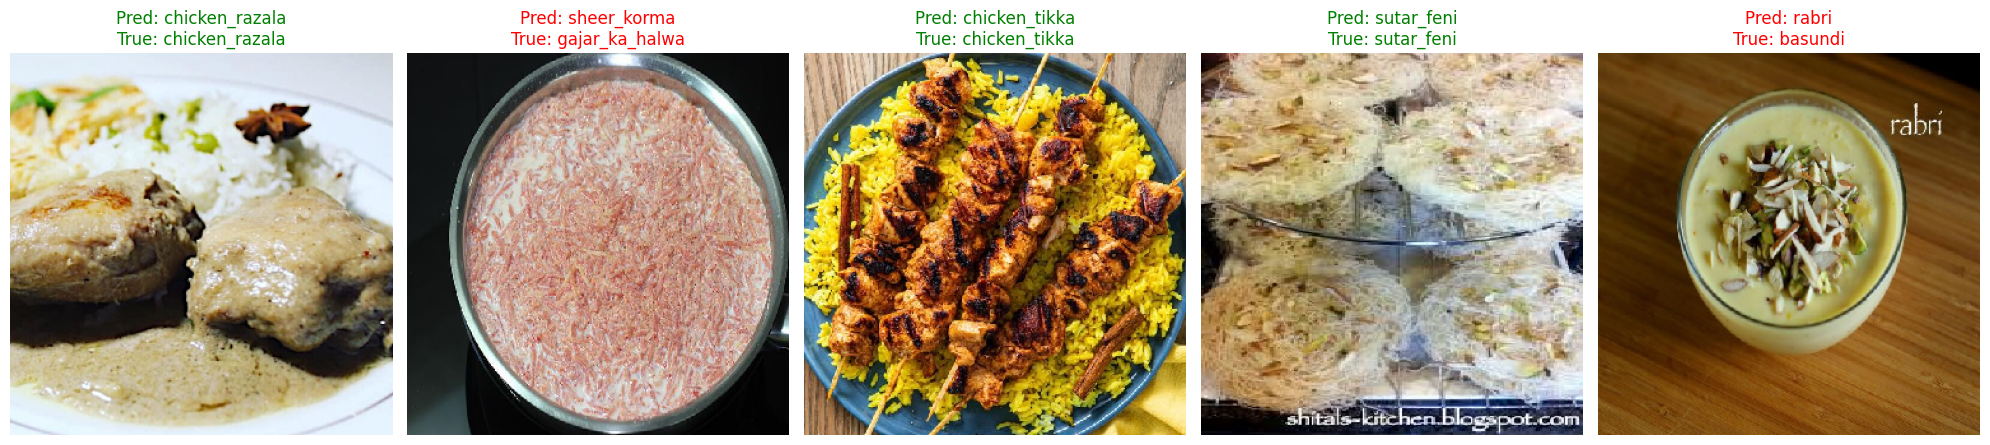

In [11]:
import matplotlib.pyplot as plt

# Get one batch of images from the test set
test_gen.reset() # Reset generator to start
x_batch, y_batch = next(test_gen)

# Get the model's predictions for this batch
predictions = model.predict(x_batch)

# Get the list of class names
class_labels = list(train_gen.class_indices.keys())

# Plot the first 5 images
plt.figure(figsize=(20, 5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    
    # Find the class with the highest probability
    pred_index = np.argmax(predictions[i])
    true_index = np.argmax(y_batch[i])
    
    pred_class = class_labels[pred_index]
    true_class = class_labels[true_index]
    
    # Display the image (Converting float back to integer for plotting)
    plt.imshow(x_batch[i].astype('uint8'))
    
    # Green title if correct, Red if wrong
    color = 'green' if pred_class == true_class else 'red'
    plt.title(f"Pred: {pred_class}\nTrue: {true_class}", color=color, fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()


2026-04-26 14:26:49.406715: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 14:26:49.541277: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 14:26:49.840104: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 14:26:49.981051: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 14:26:50.782443: E external/local_xla/xla/stream_

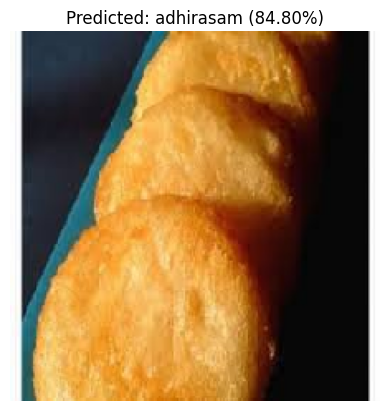

In [12]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

def predict_food(image_path):
    # 1. Load the image and resize it to what the model expects (224x224)
    img = image.load_img(image_path, target_size=(224, 224))
    
    # 2. Convert image to numpy array
    img_array = image.img_to_array(img)
    
    # 3. Add a batch dimension (model expects shape: (batch_size, 224, 224, 3))
    # Even for a single image, it needs to be in a "batch" of 1
    img_batch = np.expand_dims(img_array, axis=0)
    
    # 4. Run prediction
    predictions = model.predict(img_batch, verbose=0)
    
    # 5. Find the index with the highest probability
    predicted_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100
    
    # 6. Map the index back to the actual food name
    # We get the list of class names from the generator
    class_labels = list(train_gen.class_indices.keys())
    predicted_food = class_labels[predicted_index]
    
    # 7. Display the image and the result
    plt.imshow(img_array.astype('uint8'))
    plt.axis('off')
    plt.title(f"Predicted: {predicted_food} ({confidence:.2f}%)")
    plt.show()
    
    return predicted_food

# --- Example Usage ---
# Just pass the path to any image on your computer!
# sample_path = df['filepaths'].iloc[0] # Grabbing a random image from your dataframe
result = predict_food("/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images/adhirasam/02d09e872d.jpg")


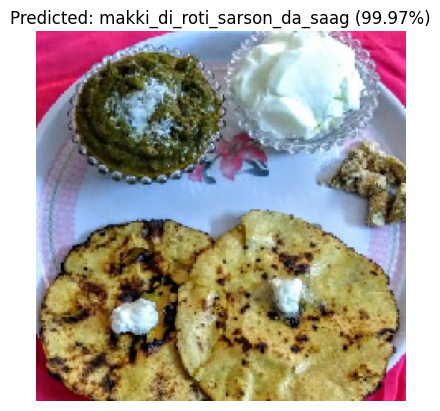

In [13]:
sample_path = df['filepaths'].iloc[0] # Grabbing a random image from your dataframe
result = predict_food(sample_path)

In [14]:
model.save("indian_food_model_v2.keras")


In [15]:
from IPython.display import FileLink
FileLink('indian_food_model_v2.keras')


/kaggle/working/indian_food_model_v2.keras

In [21]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

In [22]:
MODEL_PATH = '/kaggle/input/datasets/dheerajmalavath/indian-food-model-v2-keras/indian_food_model_v2.keras' # Change if saved as .h5
print(f"Loading model from {MODEL_PATH}...")

model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded successfully!")

Loading model from /kaggle/input/datasets/dheerajmalavath/indian-food-model-v2-keras/indian_food_model_v2.keras...
Model loaded successfully!


In [23]:
# UPDATE THIS PATH to wherever your dataset folders are stored
DATASET_DIR = '/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images'

class_labels = []
if os.path.exists(DATASET_DIR):
    class_labels = sorted(os.listdir(DATASET_DIR))
    print(f"Loaded {len(class_labels)} class labels.")
else:
    print("Dataset directory not found. Please update DATASET_DIR above.")
    print("The model will output Class IDs instead of names until the path is fixed.")

Loaded 80 class labels.


In [27]:
def detect_food(image_path):
    if not os.path.exists(image_path):
        print(f"Error: Image not found at {image_path}")
        return
        
    # Load and resize the image to exactly what EfficientNet expects
    img = image.load_img(image_path, target_size=(300, 300))
    img_array = image.img_to_array(img)
    
    # Add batch dimension (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)
    
    # Run prediction
    predictions = model.predict(img_batch, verbose=0)
    
    # Get highest probability index and confidence
    predicted_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100
    
    # Get the human-readable food name
    if len(class_labels) > 0:
        predicted_food = class_labels[predicted_index]
    else:
        predicted_food = f"Class ID {predicted_index}"
        
    # Display results
    plt.figure(figsize=(6, 6))
    plt.imshow(img_array.astype('uint8'))
    plt.axis('off')
    plt.title(f"Detected: {predicted_food} ({confidence:.2f}%)", fontsize=16, color='darkblue')
    plt.show()
    
    return predicted_food

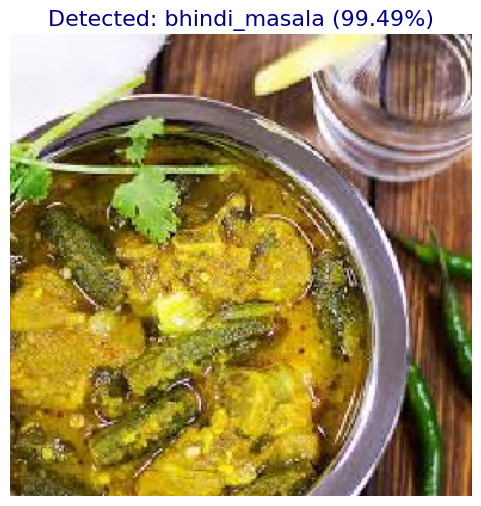

'bhindi_masala'

In [31]:
# Test the model on a new image
test_image = "/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images/bhindi_masala/9eb7a27bdc.jpg" 

detect_food(test_image)

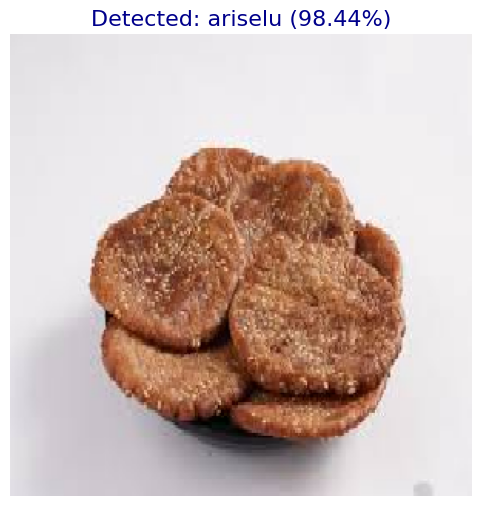

'ariselu'

In [30]:
# Test the model on a new image
test_image1 = "/kaggle/input/datasets/dheerajmalavath/pic2jpg/pic2.jpg" 

detect_food(test_image1)